In [23]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import pandas as pd

In [24]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [25]:
X= df.drop(columns=["charges"])
y= df["charges"]

In [26]:
X = pd.get_dummies(X, columns=["region"], drop_first=True, dtype=int)

X["sex"] = X["sex"].map({"female":1 , "male":0})
X["smoker"] = X["smoker"].map({"yes":1 , "no":0})

X["age_smoker"] = X["smoker"] * X["age"]
X["bmi_smoker"] = X["smoker"] * X["bmi"]
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2 ,random_state=42)

MSE for aplha=0.001: 20922599.87103596
MSE for aplha=0.1: 20921803.698431373
MSE for aplha=2: 20908106.77995452
MSE for aplha=4: 20896130.81113565
MSE for aplha=5: 20890881.000633497
MSE for aplha=20: 20877828.532378826
MSE for aplha=30: 20937537.133939773
MSE for aplha=40: 21046489.29389078
MSE for aplha=50: 21196929.86960891


<Axes: >

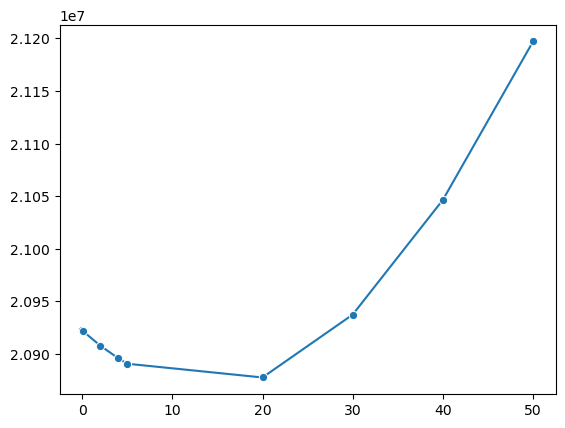

In [27]:
import seaborn as sns
alphas = [0.001,0.1,2,4,5,20,30,40,50]
mses=[]
for a in alphas:
    lasso_model = Lasso(alpha=a)

    lasso_model.fit(X_train, y_train)

    y_pred = lasso_model.predict(X_test)
    MSE = mean_squared_error(y_test, y_pred)

    print(f"MSE for aplha={a}:", MSE)

    mses.append(MSE)

sns.lineplot(x=alphas, y=mses, marker = "o")

In [35]:
from sklearn.linear_model import LassoCV
a = [0.001,0.1,2,4,5,20,30,40,50]

lasso_CV_model = LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state=42
)

lasso_CV_model.fit(X_train,y_train)
print("best alpha : ", lasso_CV_model.alpha_)

y_pred = lasso_CV_model.predict(X_test)

Final_mse = mean_squared_error(y_test,y_pred)

print("MSE=",Final_mse)

best alpha :  0.001
MSE= 20922599.87103596
